# S6 · Identification and empirical support

Partners were assigned at random within each classroom and round. This
notebook checks that children’s own characteristics do not predict the
rank of the partners they met, that rank differences are spread over the
whole session, and that every classroom and friendship group has enough
variation in rank gaps. Code: `code/si/S6_identification.R`.

In [ ]:
here::i_am("notebooks/si/S6_identification.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}

## Three measures of exposure

The raw gap mixes the partner’s rank with the child’s own rank, so it is
not a clean balance check. The demeaned partner rank compares the
partner with the rank the child could expect in that classroom and
round.

In [ ]:
# Three versions of the exposure of the focal child (the sender):
#   raw_gap               partner rank - own rank  (higher = met a higher-ranked partner)
#   partner_rank          the partner's rank only
#   partner_rank_demeaned partner rank - the rank she could expect: the mean
#                         rank of the other children active in that class-round
balance_data <- dyads %>%
  left_join(students %>% select(sender_id = student_id, female, attendance_z, gpa), by = "sender_id") %>%
  mutate(class_round  = factor(paste(class_id, round, sep = "_")),
         raw_gap      = receiver_rank - sender_rank,
         partner_rank = receiver_rank) %>%
  group_by(class_round) %>%
  mutate(expected_partner_rank = (sum(sender_rank) - sender_rank) / (n() - 1),
         partner_rank_demeaned = partner_rank - expected_partner_rank) %>%
  ungroup()

outcomes <- c(raw_gap = "A: Social Rank GAP (partner - sender)",
              partner_rank = "B: Partner Rank",
              partner_rank_demeaned = "C: Partner Rank (demeaned)")

## Table S16. Balance

In [ ]:
# Table S16: each outcome on each covariate alone (1-3) and on all three (4),
# with classroom-by-round FE and SE clustered by classroom
covariate_sets <- list("(1)" = "female", "(2)" = "attendance_z", "(3)" = "gpa",
                       "(4)" = "female + attendance_z + gpa")

balance_models <- expand_grid(outcome = names(outcomes), model = names(covariate_sets)) %>%
  mutate(fit = map2(outcome, model, ~ felm(
    as.formula(paste(.x, "~", covariate_sets[[.y]], "| class_round | 0 | class_id")),
    data = balance_data)))

table_s16 <- balance_models %>%
  mutate(coefs = map(fit, ~ summary(.x)$coefficients %>% as_tibble(rownames = "term")),
         r2 = map_dbl(fit, ~ summary(.x)$r.squared)) %>%
  select(-fit) %>%
  unnest(coefs) %>%
  transmute(panel = outcomes[outcome], model, term, estimate = Estimate,
            se = `Cluster s.e.`, p_value = `Pr(>|t|)`, r2)

table_s16 %>%
  mutate(cell = paste0(sprintf("%.4f", estimate), stars(p_value), " (", sprintf("%.4f", se), ")")) %>%
  select(panel, term, model, cell) %>%
  pivot_wider(names_from = model, values_from = cell, values_fill = "")

panel,term,(1),(2),(3),(4)
A: Social Rank GAP (partner - sender),female,0.0171 (0.0244),,,0.0462 (0.0242)
A: Social Rank GAP (partner - sender),attendance_z,,-0.0255** (0.0085),,0.0059 (0.0079)
A: Social Rank GAP (partner - sender),gpa,,,-0.1692*** (0.0279),-0.1784*** (0.0275)
B: Partner Rank,female,0.0005 (0.0014),,,0.0022 (0.0014)
B: Partner Rank,attendance_z,,-0.0019** (0.0006),,-0.0000 (0.0005)
B: Partner Rank,gpa,,,-0.0103*** (0.0019),-0.0105*** (0.0018)
C: Partner Rank (demeaned),female,-0.0001 (0.0003),,,-0.0002 (0.0003)
C: Partner Rank (demeaned),attendance_z,,-0.0000 (0.0002),,-0.0001 (0.0002)
C: Partner Rank (demeaned),gpa,,,0.0004 (0.0003),0.0005 (0.0004)


## Figure S15. Coefficients on a common scale

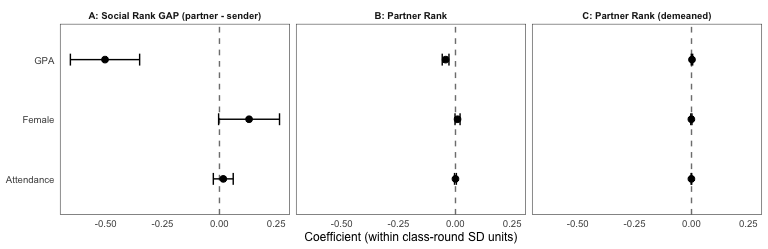

In [ ]:
# Coefficients of model (4) divided by the within-class-round SD of each
# outcome, so the three outcomes share a scale
outcome_sd <- balance_data %>%
  group_by(class_round) %>%
  mutate(across(all_of(names(outcomes)), ~ .x - mean(.x))) %>%
  ungroup() %>%
  summarise(across(all_of(names(outcomes)), sd)) %>%
  pivot_longer(everything(), names_to = "outcome", values_to = "sd")

figure_s15_data <- balance_models %>%
  filter(model == "(4)") %>%
  mutate(coefs = map(fit, ~ summary(.x)$coefficients %>% as_tibble(rownames = "term"))) %>%
  select(outcome, coefs) %>% unnest(coefs) %>%
  left_join(outcome_sd, by = "outcome") %>%
  mutate(estimate = Estimate / sd, se = `Cluster s.e.` / sd,
         outcome = factor(outcomes[outcome], levels = outcomes),
         term = recode(term, female = "Female", attendance_z = "Attendance", gpa = "GPA"))

figure_s15 <- ggplot(figure_s15_data, aes(estimate, term)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey50") +
  geom_errorbarh(aes(xmin = estimate - 1.96 * se, xmax = estimate + 1.96 * se), height = 0.2) +
  geom_point(size = 2) +
  facet_wrap(~ outcome, nrow = 1) +
  labs(x = "Coefficient (within class-round SD units)", y = NULL) +
  theme_paper(9) + theme(strip.background = element_blank(), strip.text = element_text(face = "bold"))
figure_s15

## Figure S16. Round by round

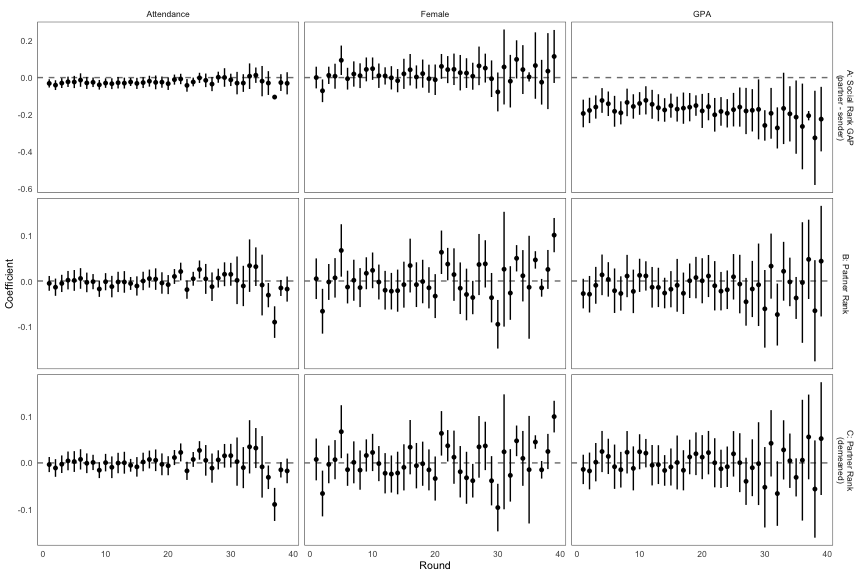

In [ ]:
# Round by round: each outcome on each covariate, classroom FE, SE by class
round_balance <- expand_grid(round_id = sort(unique(balance_data$round)),
                             outcome = names(outcomes),
                             covariate = c("female", "attendance_z", "gpa")) %>%
  mutate(result = pmap(list(round_id, outcome, covariate), function(r, y, x) {
    d <- balance_data %>% filter(round == r)
    if (n_distinct(d$class_id) < 3) return(NULL)
    fit <- felm(as.formula(paste(y, "~", x, "| class_id | 0 | class_id")), data = d)
    ct <- summary(fit)$coefficients
    tibble(estimate = ct[x, "Estimate"], se = ct[x, "Cluster s.e."])
  })) %>%
  unnest(result)

figure_s16 <- round_balance %>%
  mutate(outcome = factor(outcomes[outcome], levels = outcomes),
         covariate = recode(covariate, female = "Female", attendance_z = "Attendance", gpa = "GPA")) %>%
  ggplot(aes(round_id, estimate)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "grey50") +
  geom_pointrange(aes(ymin = estimate - 1.96 * se, ymax = estimate + 1.96 * se), size = 0.1) +
  facet_grid(outcome ~ covariate, scales = "free_y", labeller = label_wrap_gen(20)) +
  labs(x = "Round", y = "Coefficient") +
  theme_paper(8) + theme(strip.background = element_blank())
figure_s16

## Figure S17. Demeaned exposure by covariate groups

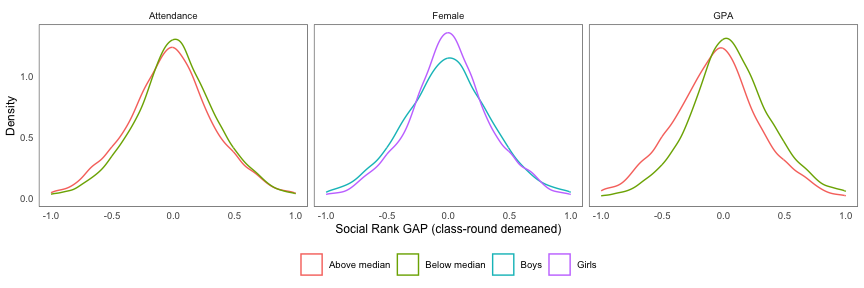

In [ ]:
# Raw exposure after removing class-round means, by covariate group
# (attendance and GPA split at their median)
density_data <- balance_data %>%
  group_by(class_round) %>% mutate(gap_demeaned = raw_gap - mean(raw_gap)) %>% ungroup() %>%
  transmute(gap_demeaned,
            Attendance = if_else(attendance_z > median(attendance_z), "Above median", "Below median"),
            GPA        = if_else(gpa > median(gpa), "Above median", "Below median"),
            Female     = if_else(female == 1, "Girls", "Boys")) %>%
  pivot_longer(-gap_demeaned, names_to = "covariate", values_to = "group")

figure_s17 <- ggplot(density_data, aes(gap_demeaned, color = group)) +
  geom_density() +
  facet_wrap(~ covariate) +
  labs(x = "Social Rank GAP (class-round demeaned)", y = "Density", color = NULL) +
  theme_paper(9) + theme(legend.position = "bottom", strip.background = element_blank())
figure_s17

## Figures S18–S19. Rank gaps by round

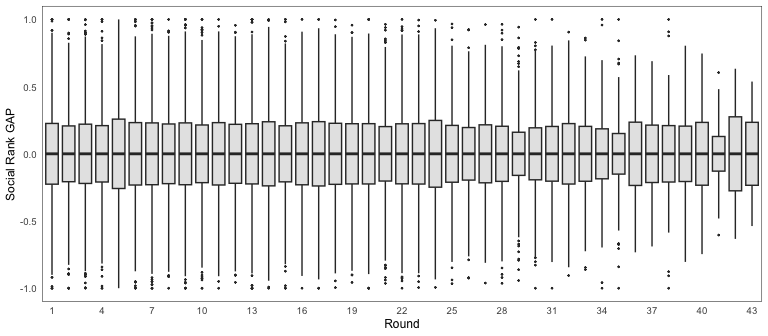

In [ ]:
figure_s18 <- ggplot(dyads, aes(factor(round), rank_gap)) +
  geom_boxplot(outlier.size = 0.2, fill = "grey90") +
  scale_x_discrete(breaks = seq(1, 43, 3)) +
  labs(x = "Round", y = "Social Rank GAP") + theme_paper(9)

figure_s19 <- dyads %>% filter(class_id == 12) %>%
  ggplot(aes(rank_gap)) +
  geom_histogram(binwidth = 0.1, fill = "grey55") +
  geom_vline(xintercept = 0, linetype = "dashed") +
  facet_wrap(~ round, ncol = 5) +
  labs(x = "Social Rank GAP", y = "Decisions") +
  theme_paper(7) + theme(strip.background = element_blank())
figure_s18

## Figure S20. By classroom

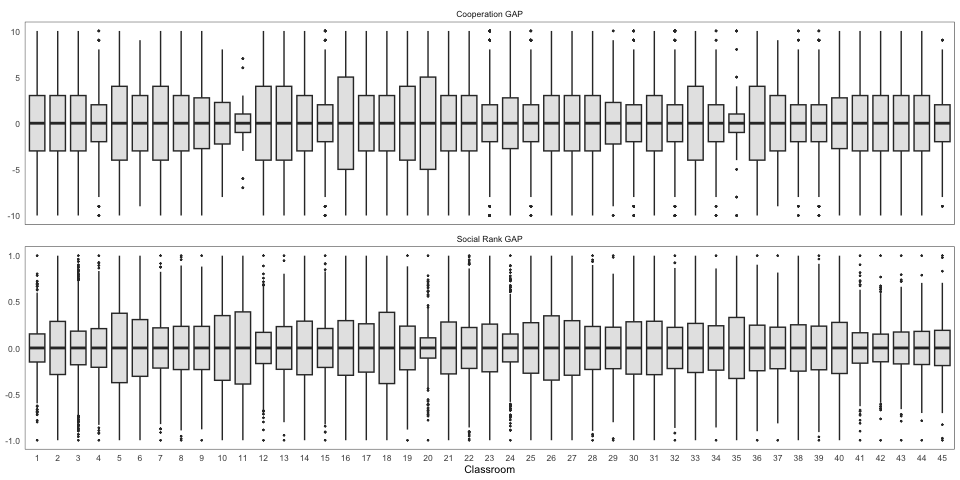

In [ ]:
figure_s20 <- dyads %>%
  select(class_id, `Social Rank GAP` = rank_gap, `Cooperation GAP` = coop_gap) %>%
  pivot_longer(-class_id) %>%
  ggplot(aes(factor(class_id), value)) +
  geom_boxplot(outlier.size = 0.2, fill = "grey90") +
  facet_wrap(~ name, ncol = 1, scales = "free_y") +
  labs(x = "Classroom", y = NULL) +
  theme_paper(8) + theme(strip.background = element_blank())
figure_s20

## Figure S21. Support among mutual friends

friendship,n,sd,share_025,share_050,classes_with_obs,classes_025,classes_050
Mutual,1288,0.2946900,35.55901,9.006211,45,45,32
Non-friends,13916,0.3605243,45.55907,17.505030,45,45,45


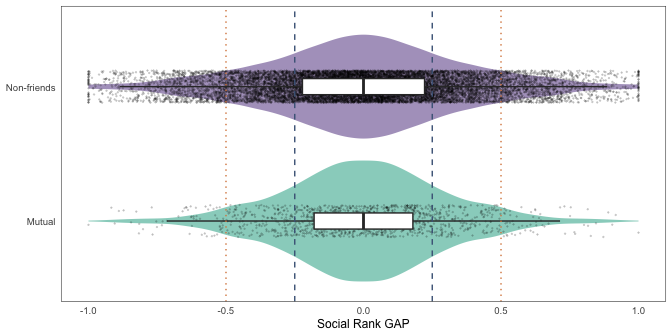

In [ ]:
# Figure S21: how much rank-gap variation mutual friendships really have
support <- dyads %>%
  filter(friendship %in% c("Non-friends", "Mutual")) %>%
  group_by(friendship) %>%
  summarise(n = n(), sd = sd(rank_gap),
            share_025 = 100 * mean(abs(rank_gap) >= 0.25),
            share_050 = 100 * mean(abs(rank_gap) >= 0.50),
            classes_with_obs = n_distinct(class_id),
            classes_025 = n_distinct(class_id[abs(rank_gap) >= 0.25]),
            classes_050 = n_distinct(class_id[abs(rank_gap) >= 0.50]))
support

In [ ]:
save_table(table_s16, "S6_table_s16_balance")
save_table(round_balance, "S6_round_balance")
save_table(support, "S6_support_by_friendship")
save_si_figure(figure_s15, "S6_figure_s15_balance_sd", 8, 2.6)
save_si_figure(figure_s16, "S6_figure_s16_round_balance", 9, 6)
save_si_figure(figure_s17, "S6_figure_s17_densities", 9, 3)
save_si_figure(figure_s18, "S6_figure_s18_gap_by_round", 8, 3.5)
save_si_figure(figure_s19, "S6_figure_s19_class12_rounds", 8, 9)
save_si_figure(figure_s20, "S6_figure_s20_by_classroom", 10, 5)
save_si_figure(figure_s21, "S6_figure_s21_support", 7, 3.5)